# Introduction à la Science de Données M1 Informatique AMU 2026/27
# TP2 - Pré-traiments des données

## 1. ACP (dans rapport à rendre)

Le rapport en pdf doit être court (max 3 pages), avec le code en annexe dans un fichier .py. Le rapport doit contenir des extraits de graphiques (voire de code si jugé nécessaire), les réponses aux questions et des conclusions qui démontrent que vous avez compris les résultats obtenus, voire que vous savez les interpréter correctement.

Nous allons maintenant nous intéresser à la méthode ACP (Analyse en Composantes Principales, PCA en anglais) pour la réduction de dimension et la visualisation. Pour cela, nous allons utiliser le jeu de données de chiffrs manuscriptes `digits`.

 ![img](https://www.tensorflow.org/images/MNIST.png)

Le jeu de données `digits` est aussi disponible dans scikit-learn. Téléchargez le jeu de données `digits`.



In [ ]:
# A vous
import numpy as np

from sklearn.datasets import load_digits

data_digits = load_digits()
labels = data_digits.target
print(data_digits.data.shape)
print(labels)

(1797, 64)
[0 1 2 ... 8 9 8]


Affichez la dimension du jeu de données.

In [ ]:
# A vous
print("dimension du jeu de données : ")
print(len(data_digits.data))

print("nombre de valeurs dans chaque vecteur: ")
print(len(data_digits.data[0]))

dimension du jeu de données : 
1797
nombre de valeurs dans chaque vecteur: 
64


Vérifiez que le jeu de données contient 1797 données, et que chaque donnée est un vecteur de 64 valeurs. Ces valeurs correspondent aux pixels d'une image de taille $8 \times 8$. Affichons quelques données.

(1797, 8, 8)


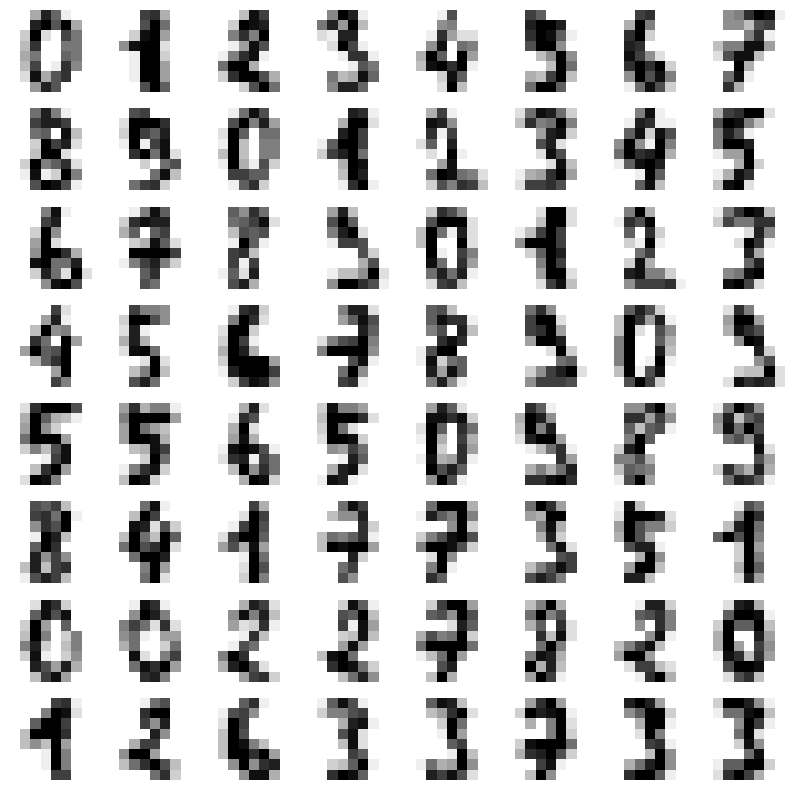

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from itertools import product


#images = data_digits.reshape(-1, 8, 8).astype(np.int_)
images = data_digits.images.astype(np.int_)
print(images.shape)

n_rows = 8
n_cols = 8

fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(10, 10))
for i, j in product(range(n_rows), range(n_cols)):
    k = n_cols * i + j
    image = images[k,0:8,0:8]
    ax[i, j].imshow(image, cmap='binary', interpolation='none')
    ax[i, j].axis('off')

plt.show()
plt.close()

Nous allons maintenant projeter les données dans un espace de plus petite dimension utilisant l'ACP. Nous pouvons par exemple les projeter dans un espace de dimension 2, et nous pourrons visualiser l'approximation produite. C'est à dire que nous allons transformer chaque donnée de dimension 64 en une donnée de dimension 2.

Il est important de se familiariser avec cette fonction ``fit_transform`` (aller voir la doc, demander au prof, etc.). Il est essentiel de comprendre le code ci-après.

In [ ]:
from sklearn import decomposition
pca = decomposition.PCA(2)  # projection dans espace à deux axes (deux dimensions)
donnees_projetes = pca.fit_transform(data_digits.data)
print(data_digits.data.shape)
print(donnees_projetes.shape)

(1797, 64)
(1797, 2)


Affichez les données projetées dans un graphique 2D, en utilisant la fonction ``scatter`` de ``matplotlib``.

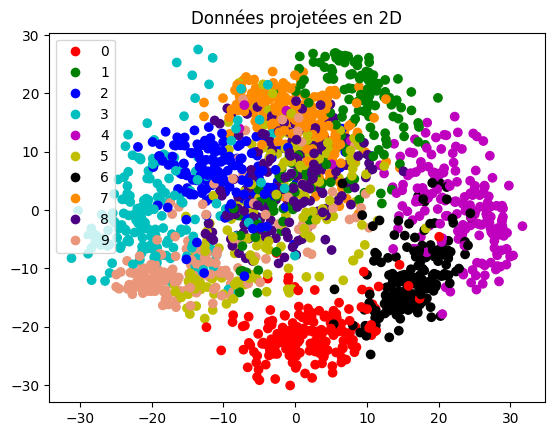

In [ ]:
# A vous
colors=["red","green","blue", "c", "m" , "y" , "k", "darkorange", "indigo", "darksalmon"]
shades = [colors[i] for i in labels] #on choisit les couleurs de chaque point
scatter = plt.scatter(donnees_projetes[:,0], donnees_projetes[:,1] , c=shades)
plt.title("Données projetées en 2D")
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors[i], markersize=8) for i in range(10)], labels=[str(i) for i in range(10)]) #légende ajustée par IA pour propreté
plt.show()

Analysez librement le résultat obtenu au regard d'une tâche de classification. Par exemple, est-il possible d'identifier les frontières entre les 10 classes de chiffres ? Quelles sont -- si le graphique est lisible -- les plus grosses confusions entre chiffres ? Faites part de vos reflexions & conclusions dans le rapport, montrez nous que vous avez compris ce que fait l'ACP sur ces données.

Refaire cette ACP mais en ne conservant les 3 premières composantes principales, et visualiser la transformation des données dans le nouvel espace obtenu. Commenter avec sens critique au regard de l'espace 2D précédent.

(1797, 64)
(1797, 3)


/usr/local/lib/python3.13/dist-packages/matplotlib/collections.py:1008: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


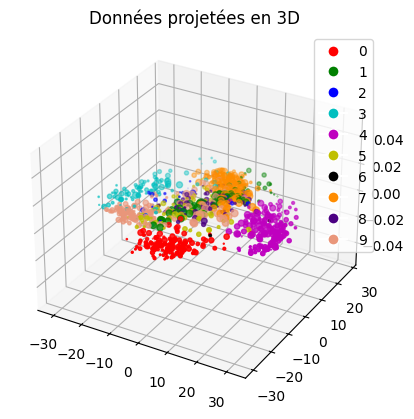

In [ ]:
# A vous
from sklearn import decomposition
pca = decomposition.PCA(3)  # projection dans espace à trois axes (trois dimensions)
donnees_projetes = pca.fit_transform(data_digits.data)
print(data_digits.data.shape)
print(donnees_projetes.shape)
colors=["red","green","blue", "c", "m" , "y" , "k", "darkorange", "indigo", "darksalmon"]
shades = [colors[i] for i in labels]
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
scatter = plt.scatter(donnees_projetes[:,0 ], donnees_projetes[:,1] , donnees_projetes[:, 2] , c=shades)
plt.title("Données projetées en 3D")
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors[i], markersize=8) for i in range(10)], labels=[str(i) for i in range(10)])
plt.show()

## 2. Gestion propre des données manquantes (dans rapport à rendre)

Ci-après, nous modifions le jeu de données digits en éliminant de façon aléatoire des valeurs de colonnes dans certains exemples. Cette élimination revient à changer la valeur concernée vers la valeur "Not a Number" (`math.nan`). Contrairement au TP1, nous n'utiliserons la fonction ``fillna``de pandas, mais nous allons programmer plusieurs variantes de cette fonction avec différents algorithmes vues en cours. A l'issue de cela, vous pourriez devenir programmeur des variantes de la fonction ``fillna`` de pandas !

Nous créons trois versions du jeu avec données manquantes pour tester 3 méthodes. Il est nécessaire de comprendre le code ci-dessous. Si soucis, n'hésitez pas à demander au prof de vous expliquer.

In [ ]:
import numpy as np
from sklearn.datasets import load_digits
import random
import math
digits = load_digits()
miss_digits = load_digits()
nbmissingvalues = random.randint(1000,2000)
for imissingvalue in range(nbmissingvalues):
    lig = random.randint(0,1763)
    col = random.randint(0,63)
    miss_digits.data[lig,col] = math.nan
mdd1 = miss_digits.data.copy() # pour tester methode 1
mdd2 = miss_digits.data.copy() # pour tester methode 2
mdd3 = miss_digits.data.copy() # pour tester methode 3

Combien de valeurs sont manquantes globalement ? Combien de valeurs sont manquantes, colonne par colonne~?

Il est conseillé d'écrire ici deux fonctions pour répondre à ces questions, chacune prenant en paramètre la matrice des données, car elles pourront être réutilisées par la suite pour vérifier que les valeurs d'une matrice ont été complétées.

In [ ]:
# A vous
def nb_missing_values(data):
    count = 0
    for i in range(len(data)):
        for j in range(len(data[0])):
            if math.isnan(data[i][j]):
                count += 1
    return count

print(f"nombre de valeurs manquantes totales : {nb_missing_values(miss_digits.data)}")

def nb_missing_values_col(data):
    count = [0 for i in range(len(data[0]))]
    for i in range(len(data)):
        for j in range(len(data[0])):
            if math.isnan(data[i][j]):
                count[j] += 1

    return count

print(f"nombre de valeurs manquantes par colonne : {nb_missing_values_col(miss_digits.data)}")

nombre de valeurs manquantes totales : 1363
nombre de valeurs manquantes par colonne : [14, 21, 16, 33, 19, 24, 23, 19, 25, 34, 17, 20, 22, 21, 16, 18, 25, 24, 20, 10, 22, 33, 18, 22, 25, 25, 21, 21, 19, 15, 17, 20, 23, 12, 16, 24, 20, 26, 22, 20, 33, 29, 14, 22, 25, 25, 26, 24, 21, 17, 24, 23, 23, 20, 11, 12, 18, 21, 29, 13, 21, 21, 22, 27]


On veut maintenant comparer trois méthodes parli des centaines pour compléter ces valeurs manquantes, et ensuite évaluer la qualité de chacune dans le cas de ces données:

1. Complétion stationnaire (valeur la plus fréquente pour cette colonne)
2. Complétion par combinaison linéaire (moyenne des valeurs de cette colonne pour la classe de l'exemple concerné)
3. Complétion par l'algorithme des $k$ plus proches voisins

Pour mesurer la qualité de chaque méthode, nous calculons le score d'écart moyen au carré $e_m$ pour chaque méthode $m$. Pour chaque ligne $i$ et colonne $j$, soit $\acute{x_{i,j}}$ la valeur imputée par $m$  à la variable $x_{i,j}$ qui était manquante. Alors nous avons $$e_m = \sum_{i,j} (x_{i,j}-\acute{x_{i,j}})^2$$
Plus $e_m$ est petit, meilleure est la méthode $m$: s'assurer de bien comprendre cela (sinon le prof est là...)

(Notons que dans le cas de cet exercice, nous avons dans `digits` les vraies valeurs qui manquent dans `miss_digits`, mais en général nous ne pouvons pas puisque les valeurs manquent. Ici, l'objectif est de comparer la qualité des méthodes dans ce cas de données. Nous verrons dans d'autres TPs comment choisir la meilleure méthode dans le cas général).

L'objectif de cet exercice est de réaliser ces trois méthodes, soit en les codant, soit en récupérant ce qui existe dans `sklearn` ou dans `pandas` (mais alors il faut être capable de lire la documentation).

Indiquer le(s) programme(s) permettant de compléter les valeurs manquantes selon les trois méthodes ci-dessus, et les ordonner de la meilleure à la moins bonne.

In [ ]:
import numpy as np
import math
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer

def completion_stationnaire(data):
    imputer = SimpleImputer(strategy='most_frequent')
    data = imputer.fit_transform(data)
    return data

def completion_lineaire(data):
    imputer = SimpleImputer(strategy='mean')
    data = imputer.fit_transform(data)
    return data

def completion_par_k(data):
    imputer = KNNImputer(n_neighbors=5, weights='uniform')
    data = imputer.fit_transform(data)
    return data

def ecart_moyen_carre(data1, data2):
    ecart = 0
    for i in range(len(data1)):
        for j in range(len(data1[0])):
            ecart += (data1[i][j] - data2[i][j])**2
    return ecart

print(f"Méthode de completion stationnaire :\n {completion_stationnaire(mdd1)}")
print(f"Méthode de completion par combinaison linéaire : \n {completion_lineaire(mdd2)}")
print(f"Méthode de completion par l'algorithme des k plus proches voisins :\n {completion_par_k(mdd3)}")
print(f"Ecart moyen au carré de la méthode de completion stationnaire :{ecart_moyen_carre(completion_stationnaire(mdd1), digits.data)}")
print(f"Ecart moyen au carré de la méthode de completion par combinaison linéaire : {ecart_moyen_carre(completion_lineaire(mdd2), digits.data)}")
print(f"Ecart moyen au carré de la méthode de completion par l'algorithme des k plus proches voisins : {ecart_moyen_carre(completion_par_k(mdd3), digits.data)}")

Méthode de completion stationnaire :
 [[ 0.  0.  5. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ... 16.  9.  0.]
 ...
 [ 0.  0.  1. ...  6.  0.  0.]
 [ 0.  0.  2. ... 12.  0.  0.]
 [ 0.  0. 10. ... 12.  1.  0.]]
Méthode de completion par combinaison linéaire : 
 [[ 0.          0.          5.         ...  0.          0.
   0.        ]
 [ 0.          0.          0.         ...  6.74099099  0.
   0.        ]
 [ 0.          0.          0.         ... 16.          9.
   0.        ]
 ...
 [ 0.          0.          1.         ...  6.          0.
   0.        ]
 [ 0.          0.          2.         ... 12.          0.
   0.        ]
 [ 0.          0.         10.         ... 12.          1.
   0.        ]]
Méthode de completion par l'algorithme des k plus proches voisins :
 [[ 0.   0.   5.  ...  0.   0.   0. ]
 [ 0.   0.   0.  ...  4.4  0.   0. ]
 [ 0.   0.   0.  ... 16.   9.   0. ]
 ...
 [ 0.   0.   1.  ...  6.   0.   0. ]
 [ 0.   0.   2.  ... 12.   0.   0. ]
 [ 0.   0.  10. 